# 04 — Out-of-Sample and Cross-Station Evaluation
Run after Notebook 03. Load the frozen models and predict 2025 without refitting or choosing parameters.

- **Known stations:** future dates at development stations.
- **Held-out stations:** stations never used for training or tuning, but with their own observed historical ozone available as predictors. This is not zero-history forecasting.
- **Persistence baseline:** tomorrow's predicted ozone equals today's observed ozone.

These are daily one-step-ahead forecasts with frozen coefficients, not a forecast of the whole year from one fixed origin. All models use identical target rows. The 2025 results are a reproduction/supplementary evaluation because they have previously been inspected.

## 1. Load the test features and frozen models

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display

# Locate code/ whether Jupyter starts in the project, code/, or code/script/.
CODE = next((p for base in [Path.cwd(), *Path.cwd().parents]
             for p in [base, base / "code"]
             if (p / "script/01_data_preparation.ipynb").exists()), None)
if CODE is None:
    raise FileNotFoundError("Open this notebook from the project directory.")
DATA = CODE / "data"
RAW = DATA / "raw"
CONFIG = DATA / "config"
PROCESSED = DATA / "processed"
RESULT = CODE / "result"
TABLES = RESULT / "tables"
FIGURES = RESULT / "figures"
MODELS = RESULT / "models"
REPORTS = RESULT / "reports"
for folder in [PROCESSED, TABLES, FIGURES, MODELS, REPORTS]:
    folder.mkdir(parents=True, exist_ok=True)
print("Project directory:", CODE)

Project directory: /Users/yigefeng/Desktop/WashU大三上/SDS4425/Project/code


In [2]:
import joblib
test = pd.read_pickle(PROCESSED / "test_2025_features.pkl.gz")
selected = pd.read_csv(TABLES / "selected_models.csv")
assert test.target_date.min() >= pd.Timestamp("2025-01-01")
assert test.target_date.max() <= pd.Timestamp("2025-12-31")
predictions, metrics = [], []

## 2. Predict using training-fitted transformations
Only `transform` and matrix prediction are used here. No scaler, spline or regression model is fitted on test observations.

In [3]:
for _, winner in selected.iterrows():
    family = winner.family
    model = joblib.load(MODELS / f"{family}_frozen.joblib")
    assert pd.Timestamp(model["train_end"]) < test.target_date.min()
    assert not set(model["training_station_ids"]) & set(test.loc[test.role == "held_out", "station_id"])
    x = test[model["numeric_features"]].to_numpy()
    if model["spline"] is not None:
        x = model["spline"].transform(x)
    x = np.column_stack([x, test[model["calendar"]]])
    x = model["scaler"].transform(x)
    prediction = model["intercept"] + x @ model["coef"]
    assert np.isfinite(prediction).all()
    out = test[["station_id", "role", "target_date", "target", "lag1"]].copy()
    out["prediction"] = prediction
    out["family"] = family
    predictions.append(out)
    for role, group in list(out.groupby("role")) + [("all", out)]:
        error = group.prediction-group.target
        baseline_error = group.lag1-group.target
        station = group.assign(ae=abs(error), bae=abs(baseline_error)).groupby("station_id")[["ae", "bae"]].mean()
        metrics.append({"family": family, "group": role, "n": len(group), "stations": group.station_id.nunique(),
                        "mae": abs(error).mean(), "rmse": np.sqrt(np.mean(error**2)), "mean_error": error.mean(),
                        "baseline_mae": abs(baseline_error).mean(), "relative_mae": abs(error).mean()/abs(baseline_error).mean(),
                        "improvement_pct": 100*(1-abs(error).mean()/abs(baseline_error).mean()),
                        "station_macro_mae": station.ae.mean(), "fraction_stations_better": (station.ae<station.bae).mean(),
                        "nonzero_coefficients": int((abs(model["coef"])>1e-8).sum())})
pred = pd.concat(predictions, ignore_index=True)
result = pd.DataFrame(metrics)
assert pred.groupby("family").size().nunique() == 1
pred.to_csv(PROCESSED / "test_predictions.csv.gz", index=False, compression="gzip")
result.to_csv(TABLES / "test_metrics.csv", index=False)
display(result[["family", "group", "n", "mae", "rmse", "relative_mae", "improvement_pct"]])

,family,group,n,mae,rmse,relative_mae,improvement_pct
0,Lasso,development,235065,5.614135,7.372098,0.914535,8.546509
1,Lasso,held_out,60750,5.575288,7.347301,0.918015,8.198534
2,Lasso,all,295815,5.606157,7.367012,0.915243,8.475655
3,OLS,development,235065,5.614670,7.372960,0.914622,8.537799
4,OLS,held_out,60750,5.575781,7.347844,0.918096,8.190421
5,OLS,all,295815,5.606683,7.367809,0.915329,8.467067
6,Ridge,development,235065,5.614908,7.372934,0.914661,8.533922
7,Ridge,held_out,60750,5.576112,7.347918,0.918150,8.184967
8,Ridge,all,295815,5.606941,7.367804,0.915371,8.462868
9,Spline_Ridge,development,235065,5.613959,7.368975,0.914506,8.549371


## 3. Interpret the error measures
- **MAE:** average absolute error, in ppb; lower is better.
- **RMSE:** square root of the mean squared error, in ppb; more sensitive to large misses.
- **Mean error:** prediction minus observation; positive means average overprediction.
- **Relative MAE:** model MAE divided by persistence MAE; below 1 means improvement.
- **Improvement (%):** 100 × (1 − Relative MAE).

Pooled MAE weights each station-day equally. Station-macro MAE weights each station equally. Development selection also averages months equally, so its numerical score is not directly interchangeable with pooled test MAE. None of these metrics is a classification accuracy percentage.

In [4]:
monthly = []
for (family, role, month), group in pred.groupby(["family", "role", pred.target_date.dt.strftime("%Y-%m")]):
    monthly.append({"family": family, "role": role, "month": month,
                    "mae": abs(group.prediction-group.target).mean(),
                    "baseline_mae": abs(group.lag1-group.target).mean()})
monthly = pd.DataFrame(monthly)
monthly.to_csv(TABLES / "monthly_test_metrics.csv", index=False)
station_metrics = pred.assign(abs_error=abs(pred.prediction-pred.target),
                              baseline_abs_error=abs(pred.lag1-pred.target)).groupby(["family", "role", "station_id"]).agg(
                                  mae=("abs_error", "mean"), baseline_mae=("baseline_abs_error", "mean"), n=("target", "size")).reset_index()
station_metrics["improvement_pct"] = 100*(1-station_metrics.mae/station_metrics.baseline_mae)
station_metrics.to_csv(TABLES / "station_test_metrics.csv", index=False)

## 4. Plot temporal and cross-station performance

In [5]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(fig)

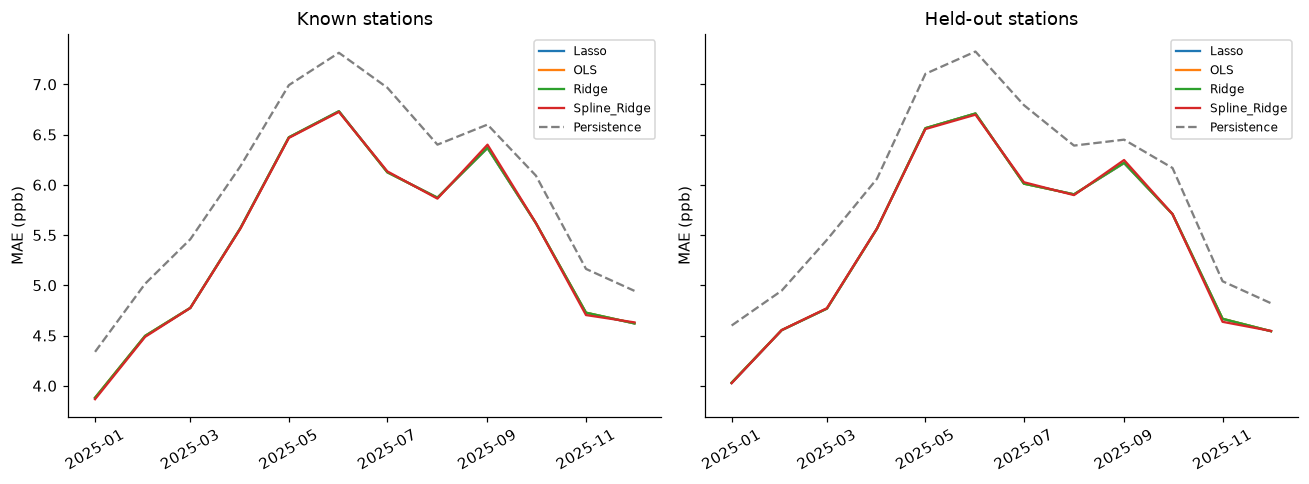

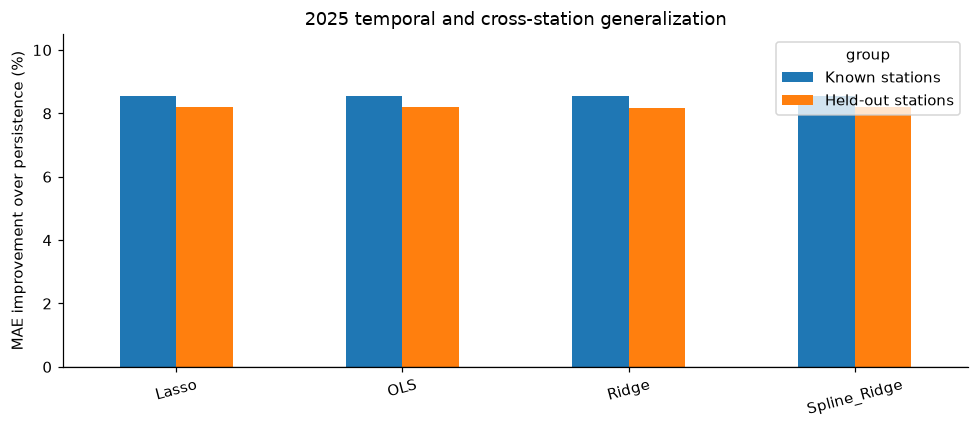

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, role in zip(axes, ["development", "held_out"]):
    for family, group in monthly[monthly.role == role].groupby("family"):
        ax.plot(pd.to_datetime(group.month), group.mae, label=family)
    baseline = monthly[(monthly.role == role) & (monthly.family == "OLS")]
    ax.plot(pd.to_datetime(baseline.month), baseline.baseline_mae, "--", color="gray", label="Persistence")
    ax.set(title="Known stations" if role == "development" else "Held-out stations", ylabel="MAE (ppb)")
    ax.legend(fontsize=8)
    ax.tick_params(axis="x", rotation=30)
save_figure(fig, "05_monthly_test_mae.png")
fig, ax = plt.subplots(figsize=(9, 4))
comparison = result[result.group != "all"].pivot(index="family", columns="group", values="improvement_pct")
comparison.rename(columns={"development": "Known stations", "held_out": "Held-out stations"}).plot.bar(ax=ax)
ax.set(ylabel="MAE improvement over persistence (%)", title="2025 temporal and cross-station generalization", xlabel="")
ax.set_ylim(0, 10.5)
ax.axhline(0, color="black", linewidth=.8)
ax.tick_params(axis="x", rotation=15)
save_figure(fig, "06_cross_station_improvement.png")

## 5. Show a reproducibly selected station example
Choose a station based on coverage, not prediction quality, and show its first 60 eligible test dates. This illustration does not replace the all-station metrics.

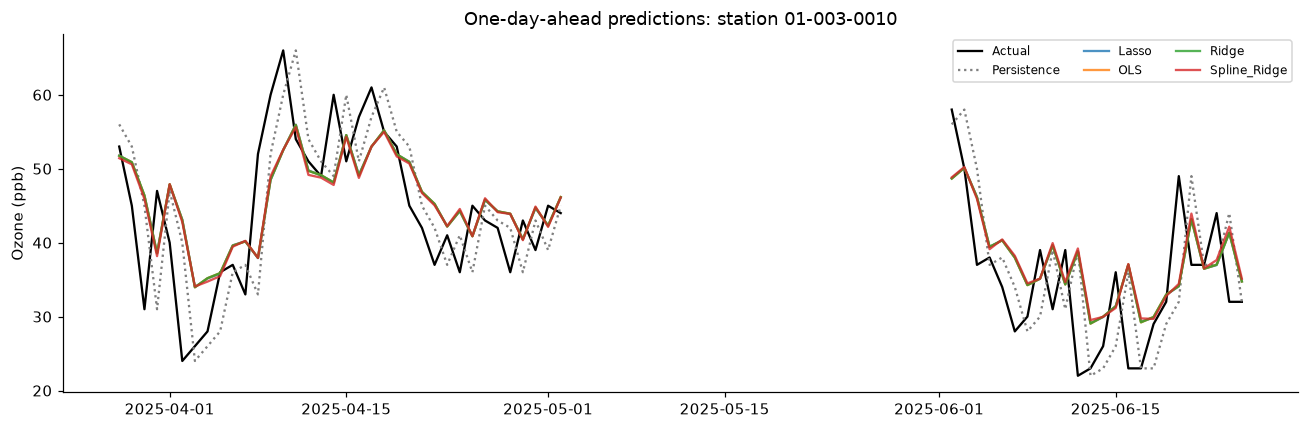

In [7]:
coverage = test[test.role == "development"].groupby("station_id").size()
station_id = sorted(coverage[coverage >= 60].index)[0]
example = pred[pred.station_id == station_id].copy()
dates = sorted(example.target_date.unique())[:60]
example = example[example.target_date.isin(dates)]
fig, ax = plt.subplots(figsize=(12, 4))
plot_dates = pd.date_range(min(dates), max(dates))
actual = example[example.family == "OLS"].set_index("target_date").reindex(plot_dates)
ax.plot(actual.index, actual.target, color="black", linewidth=1.5, label="Actual")
ax.plot(actual.index, actual.lag1, color="gray", linestyle=":", label="Persistence")
for family, group in example.groupby("family"):
    line = group.set_index("target_date").prediction.reindex(plot_dates)
    ax.plot(line.index, line.values, label=family, alpha=.8)
ax.set(title=f"One-day-ahead predictions: station {station_id}", ylabel="Ozone (ppb)")
ax.legend(ncol=3, fontsize=8)
save_figure(fig, "07_station_forecast.png")

## 6. Save the audit and a concise report
The final checks verify matching test samples, station separation, and finite predictions. The original archives are retrospective; real-time release delays are not modeled. Small model differences are descriptive and are not evidence of statistical significance.

In [8]:
audit = {"test_rows_per_family": len(test), "test_stations": test.station_id.nunique(),
         "test_previously_disclosed": True, "refit_on_test": False,
         "same_test_rows_for_all_models": True, "station_separation_checked": True,
         "checks_passed": True}
(TABLES / "evaluation_audit.json").write_text(json.dumps(audit, indent=2))
def markdown_table(frame):
    header = "| " + " | ".join(map(str, frame.columns)) + " |"
    divider = "| " + " | ".join(["---"]*len(frame.columns)) + " |"
    rows = ["| " + " | ".join(f"{v:.6f}" if isinstance(v, (float, np.floating)) else str(v) for v in row) + " |" for row in frame.itertuples(index=False, name=None)]
    return "\n".join([header, divider] + rows)
report = "# Reproduced Ozone Forecasting Results\n\n"
report += "Four frozen models; 2021–2024 development and 2025 supplementary evaluation.\n\n"
report += "## Selected configurations\n\n" + markdown_table(selected[["family", "lag", "mean_window", "std_window", "parameter", "selection_macro_mae"]])
report += "\n\n## 2025 evaluation\n\n" + markdown_table(result[["family", "group", "mae", "rmse", "relative_mae", "improvement_pct"]])
report += "\n\nHeld-out stations provide observed prior ozone histories but never enter model fitting or tuning. Models are frozen throughout 2025. Differences among model families are small. No formal significance claim is made.\n"
(REPORTS / "final_results.md").write_text(report)
display(result[result.group == "all"][["family", "mae", "rmse", "improvement_pct"]])
print("All four notebooks completed. Results are saved under code/result/.")

,family,mae,rmse,improvement_pct
2,Lasso,5.606157,7.367012,8.475655
5,OLS,5.606683,7.367809,8.467067
8,Ridge,5.606941,7.367804,8.462868
11,Spline_Ridge,5.606073,7.363907,8.477026


All four notebooks completed. Results are saved under code/result/.
